Quantum Walk with Classical Parrondo Game
-------------------------------------------------------------------------------------------------------------------------

In [1]:
from qiskit import *
import numpy as np
#Game A Probabilities
p_lose=0.505
angle=2 * np.arccos(np.sqrt(p_lose))
#Game B Probabilities
p_lose_mod3=0.905 
angle_mod3=2 * np.arccos(np.sqrt(p_lose_mod3))
p_lose_not_mod3=0.255
angle_not_mod3=2 * np.arccos(np.sqrt(p_lose_not_mod3))

In [2]:
#adder matrix operator
payoff_register_qubits=5
size = 2**payoff_register_qubits
matrix_a = np.zeros((size, size), dtype=int)
for i in range(size):
    for j in range(size):
        if j == (i - 1) % size:
            matrix_a[i, j] = 1
#print(matrix_a) # use if you want to see the matrix

In [3]:
# subtractor matrix operator
matrix_s = np.zeros((size, size), dtype=int)
for i in range(size):
    for j in range(size):
        # Flip the specific position to 1
        if j == (i + 1) % size:
            matrix_s[i, j] = 1

#print(matrix_s) #use if you want to see the matrix


In [4]:
from qiskit.circuit.library import UnitaryGate
#necessary declarations of the controlled_adder and controlled_subtractor gates for use in the quantum circuit construction
adder = UnitaryGate(matrix_a, label="AdderGate")
controlled_adder = adder.control(num_ctrl_qubits=1, ctrl_state='1')
subtractor = UnitaryGate(matrix_s, label="SubtractorGate")
controlled_subtractor = subtractor.control(num_ctrl_qubits=1, ctrl_state='0')

In [5]:
#The desired number of steps of the Quantum Walk. Each step consists of the application of Game A and Game B simultaneously.
steps=3
#Defining the Size of the Quantum Circuit in terms of the number of qubits in each register and the total number of qubits.
payoff_register_list=[]
for j in range(payoff_register_qubits):
    payoff_register_list.append(j)
ancilla_register_qubits=2 #do not change
circuit_number_of_qubits= payoff_register_qubits + ancilla_register_qubits + steps * 1
#Declaration of the Quantum Circuit and initialization of the payoff register to the state |3>
total= QuantumCircuit(circuit_number_of_qubits, name='QECPW Circuit')
total.x(4)

total.barrier()

#The Construction of the Quantum Circuit for the Quantum Parrondo's Walk.
for i in range(steps):
    game_select_register_qubit_index=payoff_register_qubits+ancilla_register_qubits+i
    #Setting Each Qubit of the Game Select Register to the Superposition State |+> to create an equal superposition of all possible game sequences.
    total.h(game_select_register_qubit_index)
    #Game A probability application to the second ancilla qubit of the Game Apply Register
    second_ancilla_qubit_index=payoff_register_qubits+ancilla_register_qubits-1
    total.cry(angle,game_select_register_qubit_index,second_ancilla_qubit_index,ctrl_state='0') 
    
    #Check if the payoff register state is mod3 or not and store the result in the first ancilla qubit of the Game Apply Register (qubit=0 if mod3, qubit=1 if NOT mod3)
    first_ancilla_qubit_index=payoff_register_qubits

    control_qubits = list(reversed(range(payoff_register_qubits)))
    total.x(first_ancilla_qubit_index)
    mod3_states = [f"{i:0{payoff_register_qubits}b}" for i in range(0, 2**payoff_register_qubits, 3)]
    for state in mod3_states:
        total.mcx(control_qubits, first_ancilla_qubit_index, ctrl_state=state)
    

    #Calculate the corresponding Game B probabilities for the mod3 case 
    total.x(first_ancilla_qubit_index) # Αντιστρέφουμε το q5 ώστε το '0' να γίνει '1' για να "νιώσει" η πύλη το control
    total.mcry(angle_mod3, [first_ancilla_qubit_index,game_select_register_qubit_index],second_ancilla_qubit_index)
    total.x(first_ancilla_qubit_index) # Επαναφέρουμε το q5 στην αρχική του κατάσταση (Uncompute)

    #Calculate the corresponding Game B probabilities for the not mod3 case 
    total.mcry(angle_not_mod3, [first_ancilla_qubit_index,game_select_register_qubit_index],second_ancilla_qubit_index)
    qubit_indices = [second_ancilla_qubit_index] + payoff_register_list
    total.append(controlled_adder, qubit_indices)
    total.append(controlled_subtractor, qubit_indices)
###################################################################################################
    total.barrier()
    total.reset(first_ancilla_qubit_index)
    total.reset(second_ancilla_qubit_index)
    total.barrier()
    

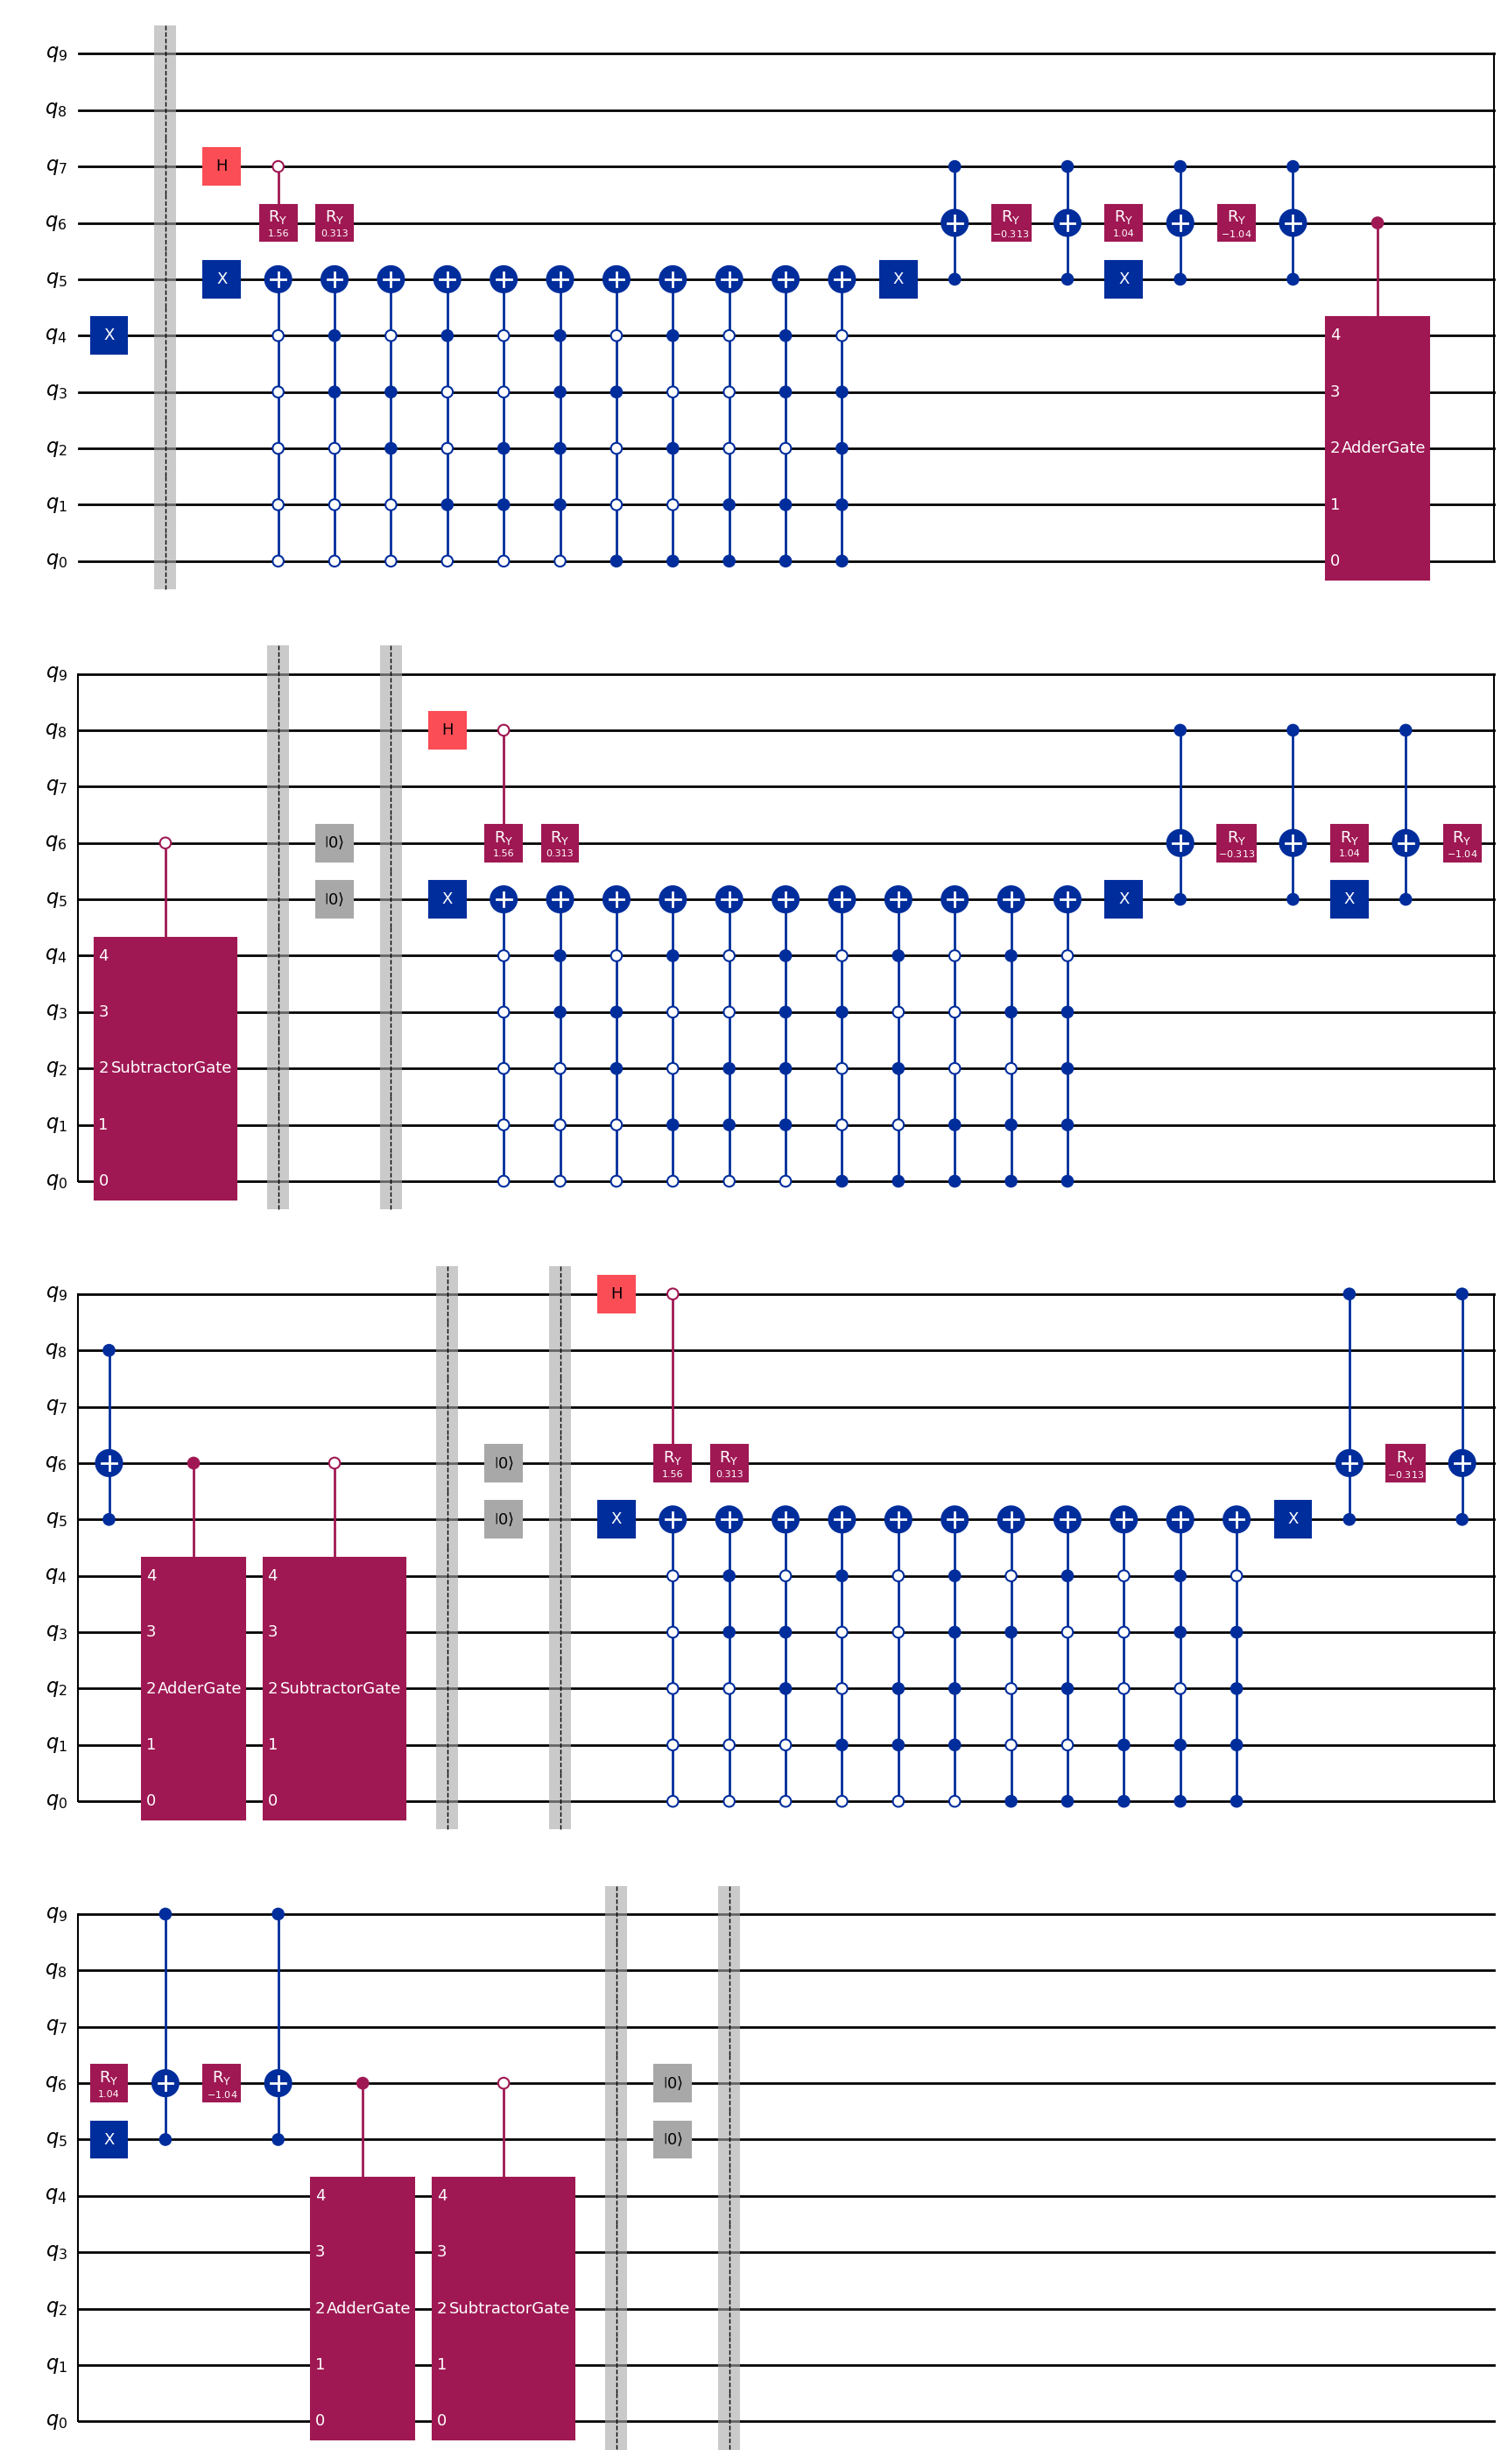

In [6]:
total.draw('mpl',reverse_bits=True)

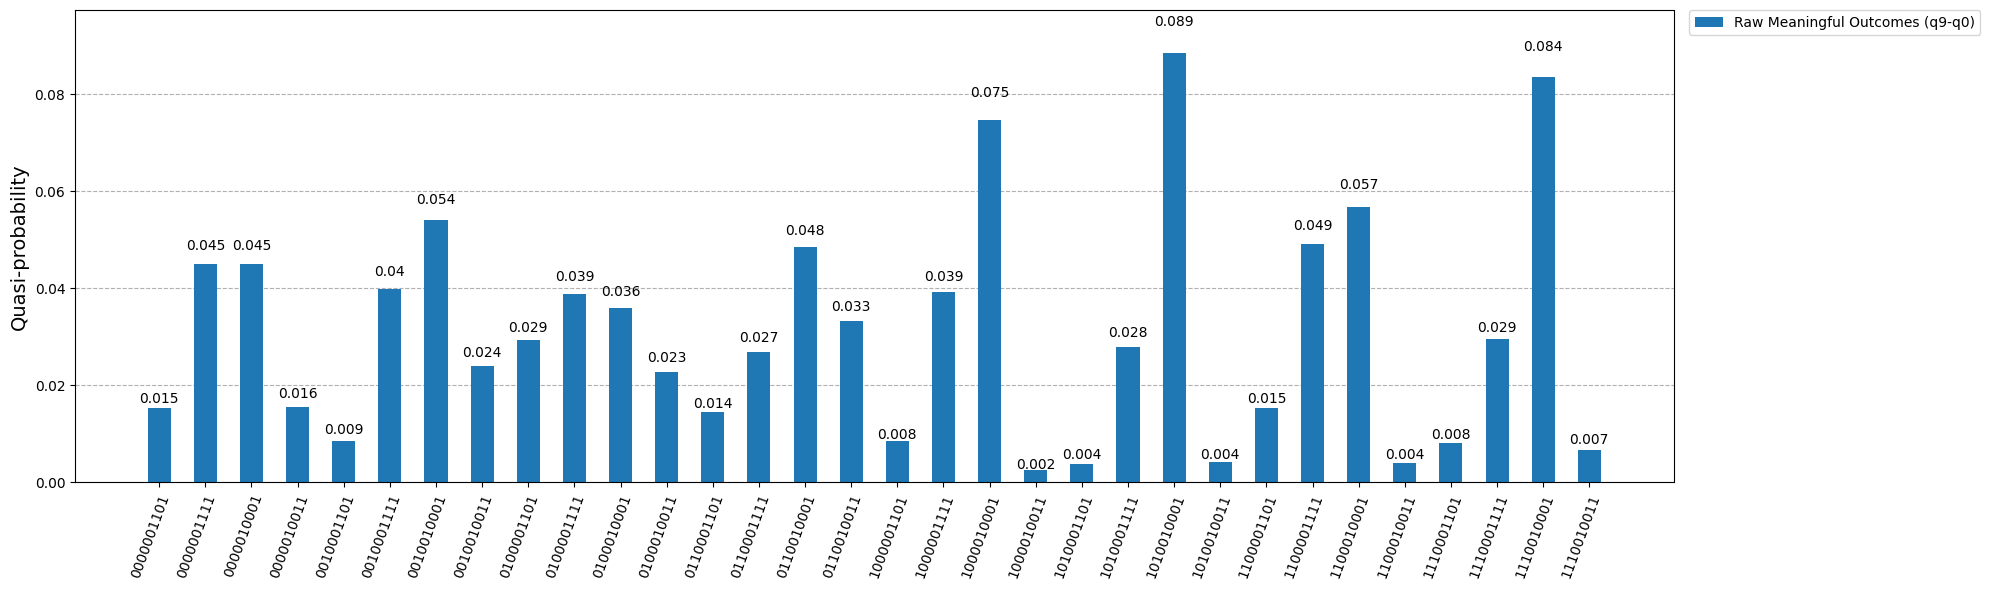

In [7]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as Sampler
from qiskit.visualization import plot_distribution
total.measure_all()
# 1. Setup and Transpile
backend = AerSimulator()
# OPTIMIZATION: Enable CPU multithreading (0 = all available cores)
sampler = Sampler(options={"backend_options": {"max_parallel_threads": 10}})
transpiled_circuit = transpile(total, backend=backend, optimization_level=3)

# 2. Run the simulation
shots = 2**15
job = sampler.run([(transpiled_circuit,)], shots=shots)
result = job.result()
pub_result = result[0]

# 3. Extract the right counts
# measure_all() creates a register named 'meas' by default.
# We pull the counts from 'meas' to see the 11-qubit string.
final_counts = pub_result.data.meas.get_counts()

# 4. Plot the 11-qubit outcomes
plot_distribution(final_counts, legend=['Raw Meaningful Outcomes (q9-q0)'], figsize=(20,6))

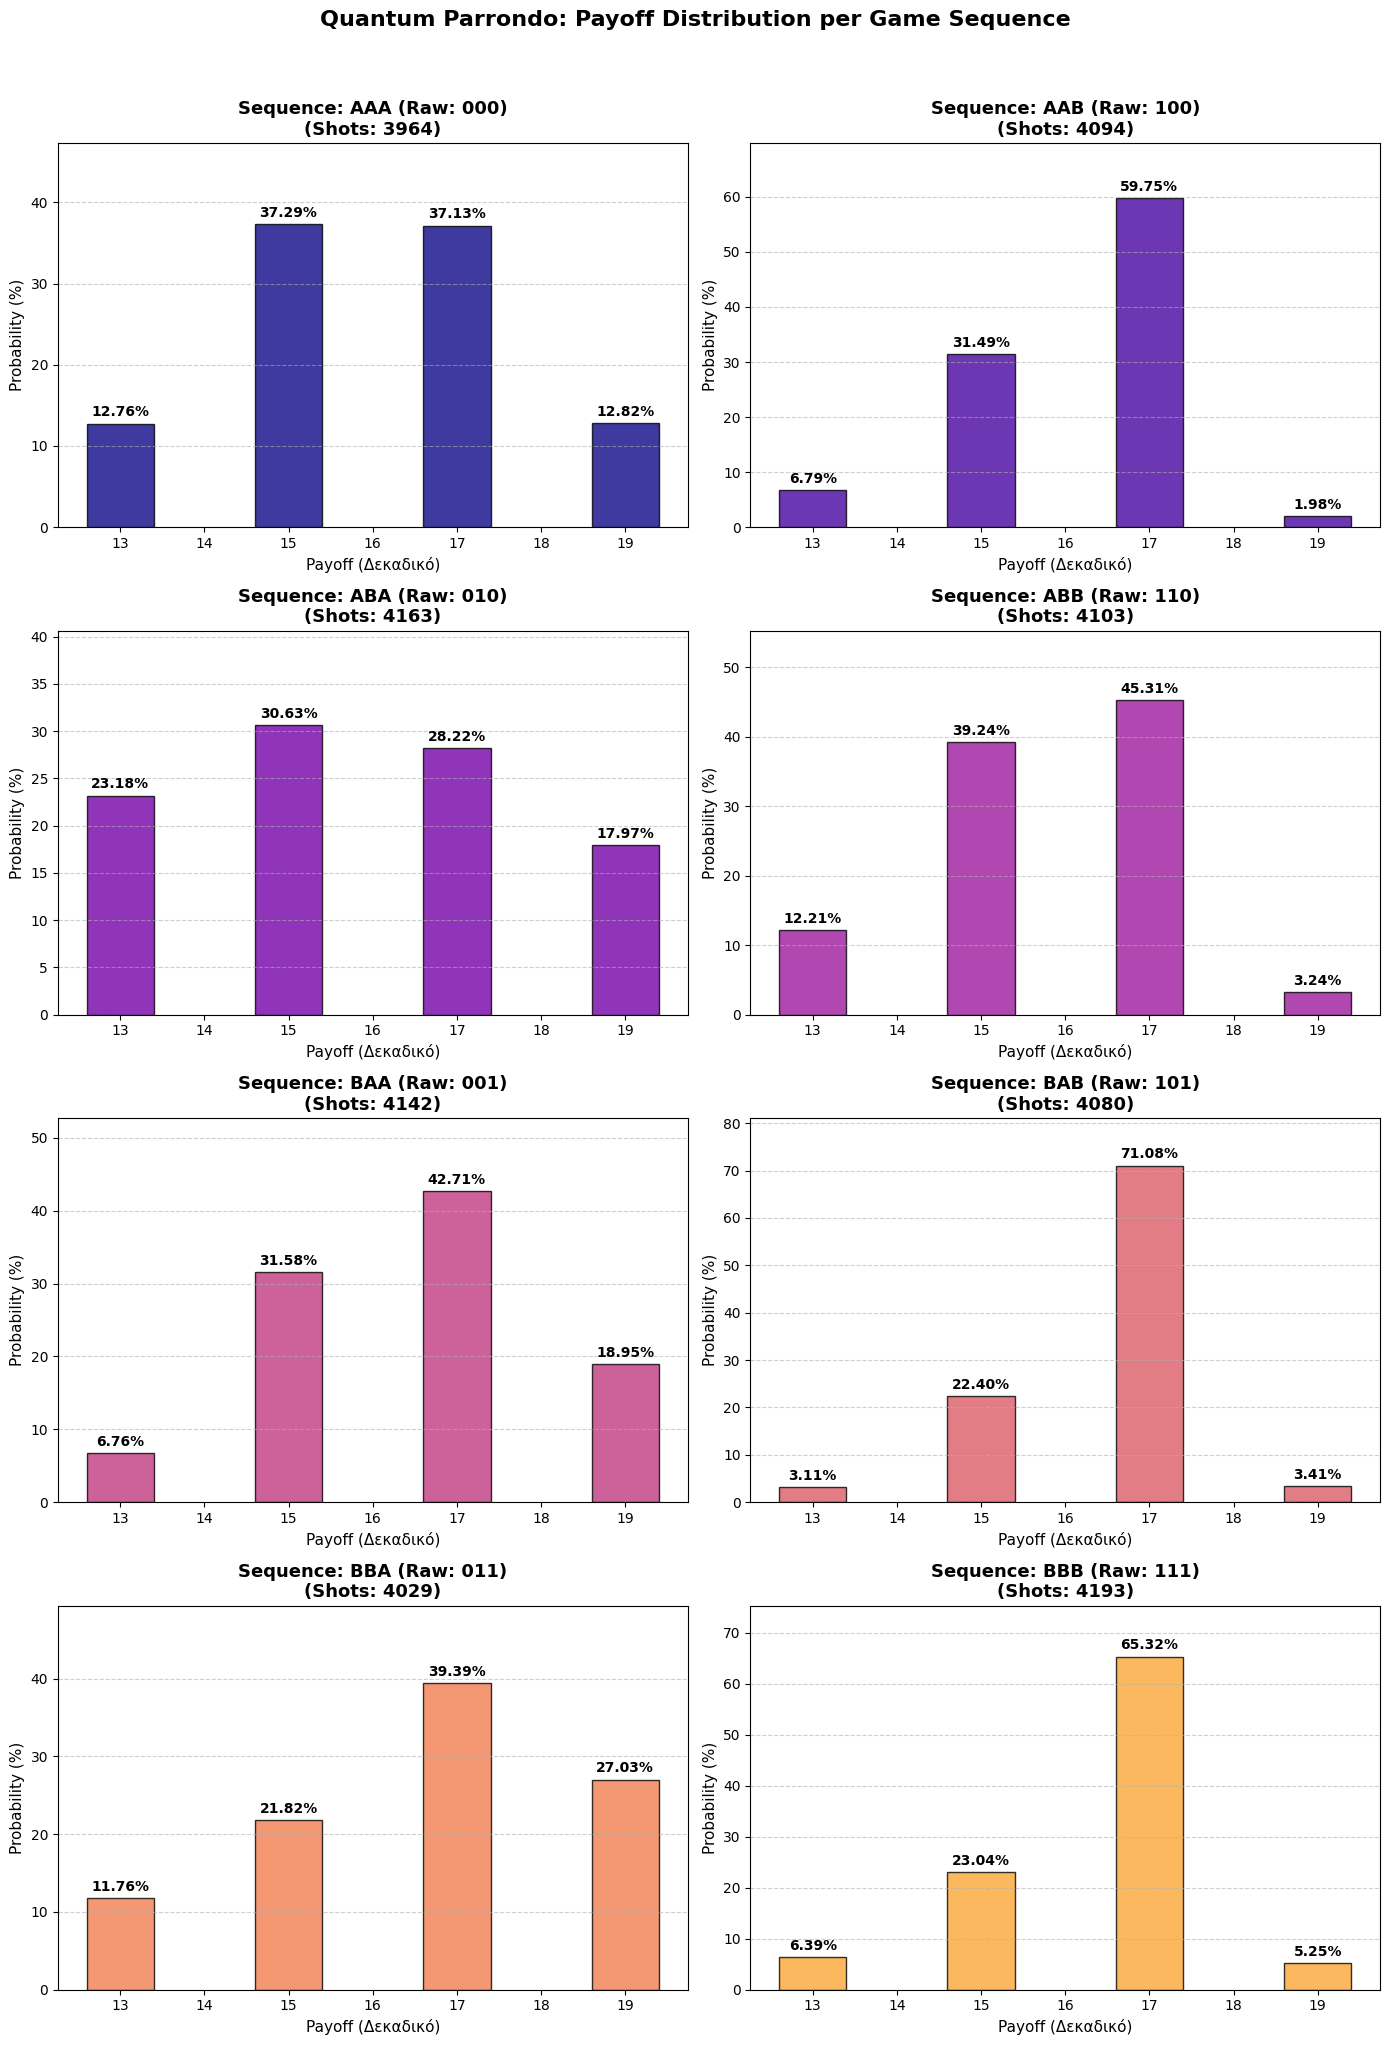

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import math

# ==========================================
# 1. Filter/Marginalize the counts (YOUR CODE)
# ==========================================
filtered_counts = {}

for bitstring, count in final_counts.items():
    q9_to_q7 = bitstring[0:steps]
    q3_to_q0 = bitstring[ancilla_register_qubits+steps:payoff_register_qubits+ancilla_register_qubits+steps] 
    new_bitstring = q9_to_q7 + q3_to_q0
    
    if new_bitstring in filtered_counts:
        filtered_counts[new_bitstring] += count
    else:
        filtered_counts[new_bitstring] = count

# ==========================================
# 2. Group by Game Sequence & Convert Formats
# ==========================================
grouped_distributions = {}

for bitstring, count in filtered_counts.items():
    # 1. Εξαγωγή δυαδικών (Το Qiskit βγάζει π.χ. '100' για AAB)
    game_seq_bin = bitstring[:steps]
    payoff_state_bin = bitstring[steps:]
    
    # 2. ΑΝΤΙΣΤΡΟΦΗ του string για να είναι χρονολογικό (Βήμα 1, Βήμα 2...)
    # Το '100' (q2, q1, q0) γίνεται '001' (q0, q1, q2)
    game_seq_chronological = game_seq_bin[::-1]
    
    # 3. Μετατροπή Παιχνιδιών πάνω στο αντεστραμμένο string (0->A, 1->B)
    game_seq_letters = game_seq_chronological.replace('0', 'A').replace('1', 'B')
    
    # Τελικό Label: π.χ. "AAB (Qiskit Raw: 100)"
    game_label = f"{game_seq_letters} (Raw: {game_seq_bin})"
    
    # Μετατροπή Payoff σε Δεκαδικό
    payoff_dec = int(payoff_state_bin, 2)
    
    if game_label not in grouped_distributions:
        grouped_distributions[game_label] = {}
        
    grouped_distributions[game_label][payoff_dec] = count

# ==========================================
# 3. Plot the Grid
# ==========================================
unique_sequences = sorted(list(grouped_distributions.keys()))
n_seq = len(unique_sequences)
cols = 2
rows = math.ceil(n_seq / cols)

fig, axes = plt.subplots(rows, cols, figsize=(14, 5 * rows))
axes = axes.flatten() if n_seq > 1 else [axes]
colors = plt.cm.plasma(np.linspace(0, 0.8, n_seq))

for idx, seq_label in enumerate(unique_sequences):
    ax = axes[idx]
    seq_data = grouped_distributions[seq_label]
    
    # Τα payoffs είναι πλέον ακέραιοι, άρα το X-axis θα είναι 100% ευθυγραμμισμένο
    payoffs_int = sorted(list(seq_data.keys()))
    counts = [seq_data[p] for p in payoffs_int]
    
    total_seq_shots = sum(counts)
    probs = [(c / total_seq_shots) * 100 for c in counts]
    
    # 1. Αποθηκεύουμε το ραβδόγραμμα στη μεταβλητή 'bars'
    bars = ax.bar(payoffs_int, probs, color=colors[idx], edgecolor='black', alpha=0.8, width=0.8)
    
    # 2. ΠΡΟΣΘΗΚΗ: Βάζουμε το ποσοστό ακριβώς πάνω από κάθε μπάρα
    # Το fmt='%.2f%%' εξασφαλίζει 2 δεκαδικά ψηφία και το σύμβολο του ποσοστού.
    # Το padding προσθέτει λίγο κενό ανάμεσα στην κορυφή της μπάρας και το κείμενο.
    ax.bar_label(bars, fmt='%.2f%%', padding=3, fontsize=10, fontweight='bold')
    
    # Επέκταση του άξονα Y λίγο προς τα πάνω για να μη "κόβονται" τα ποσοστά από το πλαίσιο
    ax.set_ylim(0, max(probs) + 10) 
    
    ax.set_title(f'Sequence: {seq_label}\n(Shots: {total_seq_shots})', fontsize=13, fontweight='bold')
    ax.set_xlabel('Payoff (Δεκαδικό)', fontsize=11)
    ax.set_ylabel('Probability (%)', fontsize=11)
    
    # Τώρα το MaxNLocator θα λειτουργήσει τέλεια γιατί ο άξονας X είναι πραγματικά νούμερα
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(axis='y', linestyle='--', alpha=0.6)

# ΔΙΟΡΘΩΣΗ ΑΣΦΑΛΕΙΑΣ: Αποφυγή NameError αν δεν τρέξει το loop
for j in range(n_seq, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Quantum Parrondo: Payoff Distribution per Game Sequence", fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()